In [17]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path("/home/bannanakid/RCRL_on_RCMDP")
ENVIRONMENT_NAME = "HalfCheetahWithPos"
RUN_NUMBER = 3
METRIC_FILE = (
    PROJECT_ROOT
    / "data_train"
    / ENVIRONMENT_NAME
    / f"run{RUN_NUMBER}"
    / "metric_calibration"
    / "baseline_metrics.npz"
)
data = np.load(METRIC_FILE, allow_pickle=False)
print(METRIC_FILE)
print(data.files)

/home/bannanakid/RCRL_on_RCMDP/data_train/HalfCheetahWithPos/run3/metric_calibration/baseline_metrics.npz
['joint_names', 'torso_pitch', 'torso_pitch_abs', 'joint_velocities', 'joint_speeds', 'actions', 'rewards', 'costs', 'episode_id', 'step_in_episode', 'episode_rewards', 'episode_costs', 'episode_max_costs', 'model_prefix', 'environment_name', 'seed', 'summary_sample_count', 'summary_pitch_mean_signed', 'summary_pitch_mean_abs', 'summary_pitch_std_abs', 'summary_pitch_p50_abs', 'summary_pitch_p90_abs', 'summary_pitch_p95_abs', 'summary_pitch_p99_abs', 'summary_pitch_max_abs', 'summary_joint_mean_abs', 'summary_joint_std_abs', 'summary_joint_p50_abs', 'summary_joint_p90_abs', 'summary_joint_p95_abs', 'summary_joint_p99_abs', 'summary_joint_max_abs', 'summary_step_max_joint_speed_mean', 'summary_step_max_joint_speed_p95', 'summary_step_max_joint_speed_p99', 'summary_step_max_joint_speed_max', 'summary_fastest_joint_counts']


In [18]:
joint_names = tuple(data["joint_names"].tolist())
torso_pitch = data["torso_pitch"]
torso_pitch_abs = data["torso_pitch_abs"]
joint_velocities = data["joint_velocities"]
joint_speeds = data["joint_speeds"]
actions = data["actions"]
rewards = data["rewards"]
costs = data["costs"]
episode_id = data["episode_id"]
step_in_episode = data["step_in_episode"]
episode_rewards = data["episode_rewards"]
episode_costs = data["episode_costs"]
episode_max_costs = data["episode_max_costs"]

print("Samples:", torso_pitch.shape[0])
print("Joint order:", joint_names)
print("Episodes:", episode_rewards.shape[0])

Samples: 100000
Joint order: ('back_thigh', 'back_shin', 'back_foot', 'front_thigh', 'front_shin', 'front_foot')
Episodes: 100


In [19]:
pitch_table = pd.DataFrame(
    {
        "metric": [
            "mean_signed_rad",
            "mean_abs_rad",
            "std_abs_rad",
            "p50_abs_rad",
            "p90_abs_rad",
            "p95_abs_rad",
            "p99_abs_rad",
            "max_abs_rad",
            "p95_abs_deg",
            "p99_abs_deg",
            "max_abs_deg",
        ],
        "value": [
            np.mean(torso_pitch),
            np.mean(torso_pitch_abs),
            np.std(torso_pitch_abs),
            np.percentile(torso_pitch_abs, 50),
            np.percentile(torso_pitch_abs, 90),
            np.percentile(torso_pitch_abs, 95),
            np.percentile(torso_pitch_abs, 99),
            np.max(torso_pitch_abs),
            np.degrees(np.percentile(torso_pitch_abs, 95)),
            np.degrees(np.percentile(torso_pitch_abs, 99)),
            np.degrees(np.max(torso_pitch_abs)),
        ],
    }
).set_index("metric")
pitch_table

,value
metric,
mean_signed_rad,0.034202
mean_abs_rad,0.163622
std_abs_rad,0.385984
p50_abs_rad,0.097529
p90_abs_rad,0.229958
p95_abs_rad,0.242906
p99_abs_rad,2.980777
max_abs_rad,2.993811
p95_abs_deg,13.917509


In [20]:
joint_table = pd.DataFrame(
    {
        "joint": joint_names,
        "mean_abs_rad_s": np.mean(joint_speeds, axis=0),
        "std_abs_rad_s": np.std(joint_speeds, axis=0),
        "p50_abs_rad_s": np.percentile(joint_speeds, 50, axis=0),
        "p90_abs_rad_s": np.percentile(joint_speeds, 90, axis=0),
        "p95_abs_rad_s": np.percentile(joint_speeds, 95, axis=0),
        "p99_abs_rad_s": np.percentile(joint_speeds, 99, axis=0),
        "max_abs_rad_s": np.max(joint_speeds, axis=0),
    }
).set_index("joint")
joint_table

,mean_abs_rad_s,std_abs_rad_s,p50_abs_rad_s,p90_abs_rad_s,p95_abs_rad_s,p99_abs_rad_s,max_abs_rad_s
joint,,,,,,,
back_thigh,5.491636,2.523381,5.937108,8.497806,8.864684,9.178360,9.689759
back_shin,4.388313,2.288071,4.150810,8.143096,9.051396,9.849941,11.573873
back_foot,4.607927,2.557217,4.221336,7.793319,7.976233,8.201312,12.510167
front_thigh,7.624556,3.534306,8.028227,12.520830,13.062712,13.460627,14.079910
front_shin,4.239708,1.931368,4.101123,6.927378,7.219767,7.454265,10.825742
front_foot,6.927566,2.969215,6.101303,10.796566,11.186432,11.684915,14.640990


In [21]:
episode_table = pd.DataFrame(
    {
        "episode": np.arange(1, len(episode_rewards) + 1),
        "reward": episode_rewards,
        "total_original_cost": episode_costs,
        "maximum_original_cost": episode_max_costs,
    }
).set_index("episode")
episode_table

,reward,total_original_cost,maximum_original_cost
episode,,,
1,3450.431668,35.979912,0.077007
2,2159.395631,23.253289,0.167039
3,3444.781062,36.025445,0.076204
4,3397.432291,35.338768,0.075965
5,3447.491559,35.019398,0.076606
...,...,...,...
96,3468.298187,36.173360,0.079791
97,3500.300032,36.189151,0.227448
98,3479.750476,36.042984,0.076414


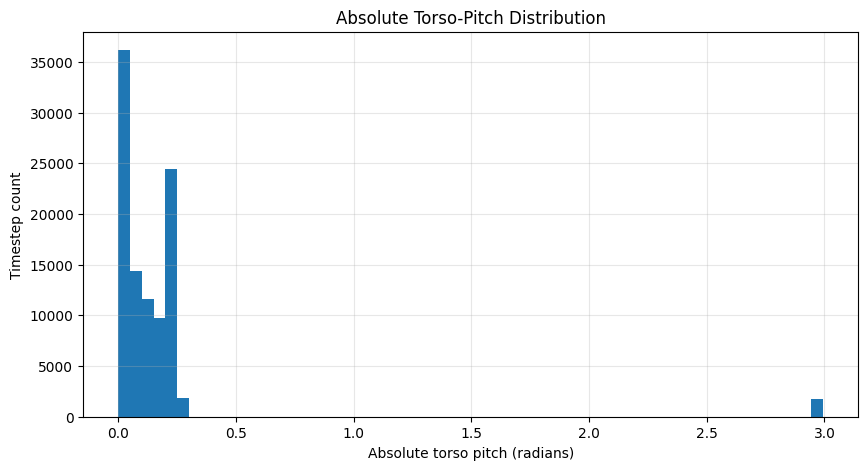

In [22]:
plt.figure(figsize=(10, 5))
plt.hist(torso_pitch_abs, bins=60)
plt.xlabel("Absolute torso pitch (radians)")
plt.ylabel("Timestep count")
plt.title("Absolute Torso-Pitch Distribution")
plt.grid(True, alpha=0.3)
plt.show()

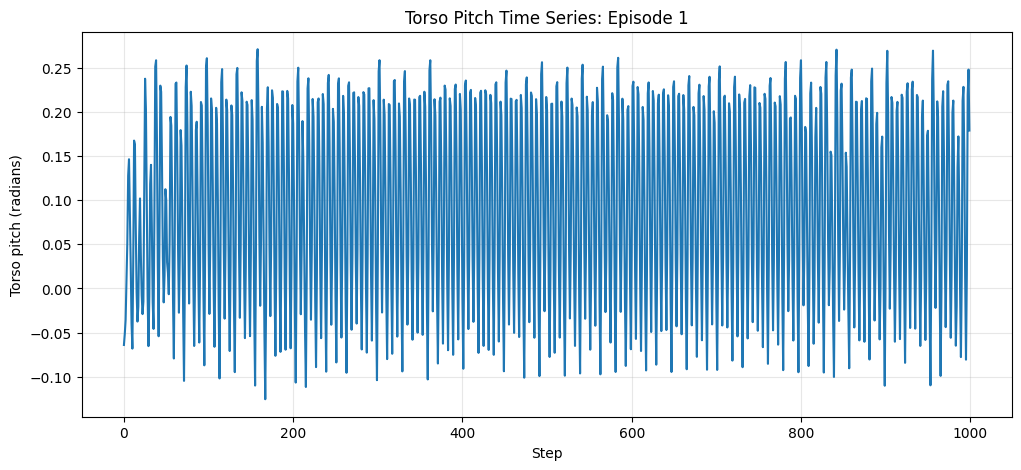

In [23]:
selected_episode = 0
mask = episode_id == selected_episode

plt.figure(figsize=(12, 5))
plt.plot(step_in_episode[mask], torso_pitch[mask])
plt.xlabel("Step")
plt.ylabel("Torso pitch (radians)")
plt.title(f"Torso Pitch Time Series: Episode {selected_episode + 1}")
plt.grid(True, alpha=0.3)
plt.show()

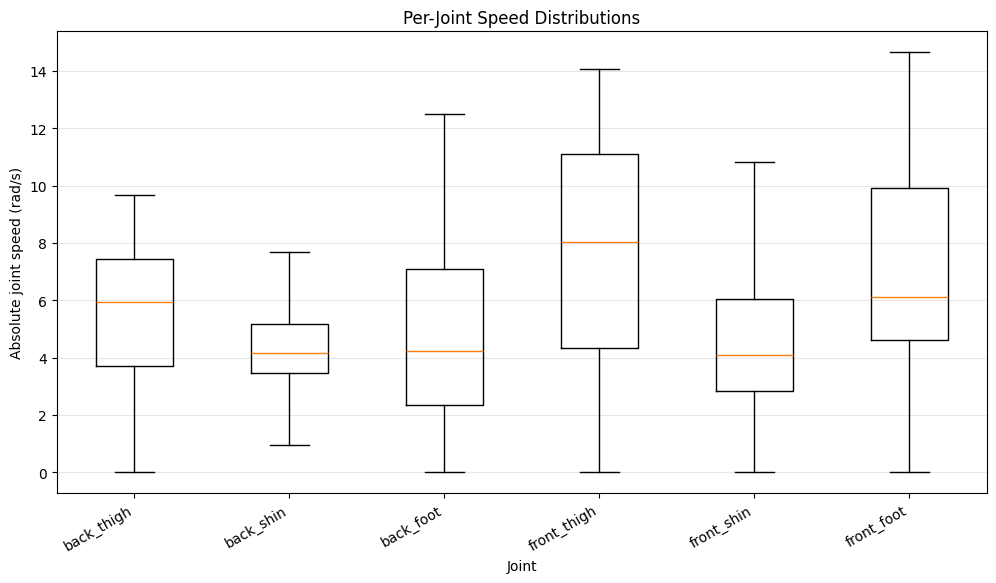

In [24]:
plt.figure(figsize=(12, 6))
plt.boxplot(
    [joint_speeds[:, index] for index in range(len(joint_names))],
    tick_labels=joint_names,
    showfliers=False,
)
plt.xlabel("Joint")
plt.ylabel("Absolute joint speed (rad/s)")
plt.title("Per-Joint Speed Distributions")
plt.xticks(rotation=30, ha="right")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

In [25]:
fastest_joint_index = np.argmax(joint_speeds, axis=1)
fastest_counts = np.bincount(
    fastest_joint_index,
    minlength=len(joint_names),
)
fastest_table = pd.DataFrame(
    {
        "joint": joint_names,
        "fastest_timestep_count": fastest_counts,
        "fraction": fastest_counts / fastest_counts.sum(),
    }
).set_index("joint")
fastest_table

,fastest_timestep_count,fraction
joint,,
back_thigh,31,0.00031
back_shin,9346,0.09346
back_foot,15686,0.15686
front_thigh,33335,0.33335
front_shin,453,0.00453
front_foot,41149,0.41149


In [26]:
pitch_thresholds = np.linspace(0.10, 0.70, 25)
pitch_sweep = pd.DataFrame(
    {
        "threshold_rad": pitch_thresholds,
        "threshold_deg": np.degrees(pitch_thresholds),
        "violation_fraction": [
            np.mean(torso_pitch_abs > threshold)
            for threshold in pitch_thresholds
        ],
    }
)
pitch_sweep

,threshold_rad,threshold_deg,violation_fraction
0,0.100,5.729578,0.49394
1,0.125,7.161972,0.43366
2,0.150,8.594367,0.37746
3,0.175,10.026761,0.33604
4,0.200,11.459156,0.27978
5,0.225,12.891550,0.12621
6,0.250,14.323945,0.03631
7,0.275,15.756339,0.01979
8,0.300,17.188734,0.01885
9,0.325,18.621128,0.01883


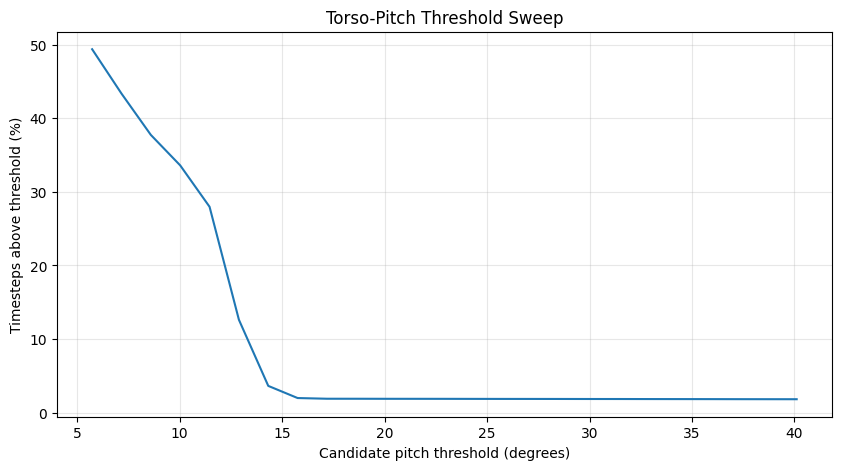

In [27]:
plt.figure(figsize=(10, 5))
plt.plot(
    pitch_sweep["threshold_deg"],
    100 * pitch_sweep["violation_fraction"],
)
plt.xlabel("Candidate pitch threshold (degrees)")
plt.ylabel("Timesteps above threshold (%)")
plt.title("Torso-Pitch Threshold Sweep")
plt.grid(True, alpha=0.3)
plt.show()

In [28]:
shared_speed_thresholds = np.linspace(
    np.percentile(joint_speeds, 75),
    np.percentile(joint_speeds, 99.9),
    30,
)
shared_speed_sweep = pd.DataFrame(
    {
        "threshold_rad_s": shared_speed_thresholds,
        "fraction_steps_any_joint_violates": [
            np.mean(np.any(joint_speeds > threshold, axis=1))
            for threshold in shared_speed_thresholds
        ],
    }
)
shared_speed_sweep

,threshold_rad_s,fraction_steps_any_joint_violates
0,7.536049,0.92495
1,7.744245,0.88432
2,7.952440,0.81916
3,8.160635,0.76874
4,8.368831,0.75105
5,8.577026,0.74449
6,8.785221,0.73675
7,8.993417,0.72578
8,9.201612,0.70886
9,9.409807,0.68715


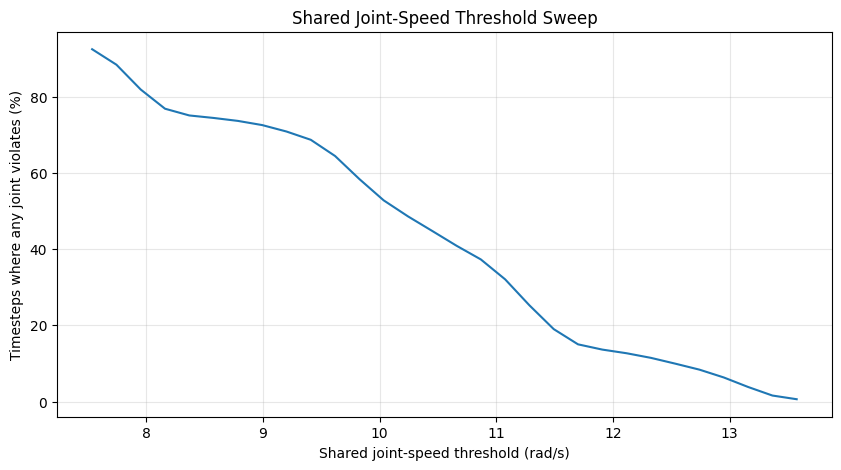

In [29]:
plt.figure(figsize=(10, 5))
plt.plot(
    shared_speed_sweep["threshold_rad_s"],
    100 * shared_speed_sweep[
        "fraction_steps_any_joint_violates"
    ],
)
plt.xlabel("Shared joint-speed threshold (rad/s)")
plt.ylabel("Timesteps where any joint violates (%)")
plt.title("Shared Joint-Speed Threshold Sweep")
plt.grid(True, alpha=0.3)
plt.show()

In [30]:
per_joint_p95 = np.percentile(joint_speeds, 95, axis=0)
per_joint_p99 = np.percentile(joint_speeds, 99, axis=0)

candidate_table = pd.DataFrame(
    {
        "joint": joint_names,
        "p95_candidate_rad_s": per_joint_p95,
        "p99_candidate_rad_s": per_joint_p99,
        "p95_violation_fraction": [
            np.mean(joint_speeds[:, index] > per_joint_p95[index])
            for index in range(len(joint_names))
        ],
        "p99_violation_fraction": [
            np.mean(joint_speeds[:, index] > per_joint_p99[index])
            for index in range(len(joint_names))
        ],
    }
).set_index("joint")
candidate_table

,p95_candidate_rad_s,p99_candidate_rad_s,p95_violation_fraction,p99_violation_fraction
joint,,,,
back_thigh,8.864684,9.178360,0.05,0.01
back_shin,9.051396,9.849941,0.05,0.01
back_foot,7.976233,8.201312,0.05,0.01
front_thigh,13.062712,13.460627,0.05,0.01
front_shin,7.219767,7.454265,0.05,0.01
front_foot,11.186432,11.684915,0.05,0.01


In [31]:
output_directory = (
    PROJECT_ROOT
    / "plot_data"
    / ENVIRONMENT_NAME
    / f"run{RUN_NUMBER}"
    / "metric_calibration"
)
output_directory.mkdir(parents=True, exist_ok=True)

pitch_table.to_csv(output_directory / "pitch_summary.csv")
joint_table.to_csv(output_directory / "joint_speed_summary.csv")
episode_table.to_csv(output_directory / "episode_summary.csv")
pitch_sweep.to_csv(
    output_directory / "pitch_threshold_sweep.csv",
    index=False,
)
shared_speed_sweep.to_csv(
    output_directory / "shared_joint_speed_threshold_sweep.csv",
    index=False,
)
candidate_table.to_csv(
    output_directory / "per_joint_speed_candidates.csv"
)

print(output_directory)

/home/bannanakid/RCRL_on_RCMDP/plot_data/HalfCheetahWithPos/run3/metric_calibration
